## Escuela Politécnica Nacional

### Facultad de Ingeniería de Sistemas

|Campo | Información |
| :--- | :--- |
| **Nombre:** | Michael Yánez |
| **Asignatura:** | Recuperación de la Información |
| **Docente:** | Ing. Ivan Carrera PhD |


**01 Revisión práctica de Machine Learning**

Propósito

Repasar los fundamentos de Machine Learning. Compararemos métodos sobre los mismos datasets y explicaremos sus resultados.

Esta práctica corresponde a una revisión de contenidos previos de Machine Learning. No requiere conocimientos de Recuperación de Información.

Objetivos

1. Distinguir clasificación, regresión, clustering, recomendación y asociación.
2. Preparar datos y separar entrenamiento, validación y prueba.
3. Comparar modelos mediante métricas apropiadas.
4. Explicar los efectos del escalamiento, los hiperparámetros y la regularización.
5. Interpretar softmax y las salidas de un MLP.
6. Identificar limitaciones y errores de los modelos.

**1. Importación y exploración incial del dataset**

**1.2. Descripción general**

In [1]:
from sklearn.datasets import load_iris
iris = load_iris()
print(iris.DESCR)

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

**1.3. Número de instancias, características, cantidad de ejemplos y dimensiones de matriz  de caracterisitcas y vector de etiquetas**

In [3]:
import pandas as pd
from sklearn.datasets import load_iris

iris = load_iris()

df_resumen = pd.DataFrame({
    'Concepto': [
        'Número de Instancias',
        'Número de Características',
        'Dimensiones de X (data)',
        'Dimensiones de y (target)',
        'Nombres de Características',
        'Nombres de Clases'
    ],
    'Detalle / Valor': [
        iris.data.shape[0],
        iris.data.shape[1],
        str(iris.data.shape),
        str(iris.target.shape),
        ', '.join(iris.feature_names),
        ', '.join(iris.target_names)
    ]
})

df_resumen

,Concepto,Detalle / Valor
0,Número de Instancias,150
1,Número de Características,4
2,Dimensiones de X (data),"(150, 4)"
3,Dimensiones de y (target),"(150,)"
4,Nombres de Características,"sepal length (cm), sepal width (cm), petal len..."
5,Nombres de Clases,"setosa, versicolor, virginica"


**1.4. tabla de 5 ejemplos**

In [4]:

df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["especie"] = iris.target_names[iris.target]
df.head()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),especie
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


**1.5. Gráfico de distribución de clases**

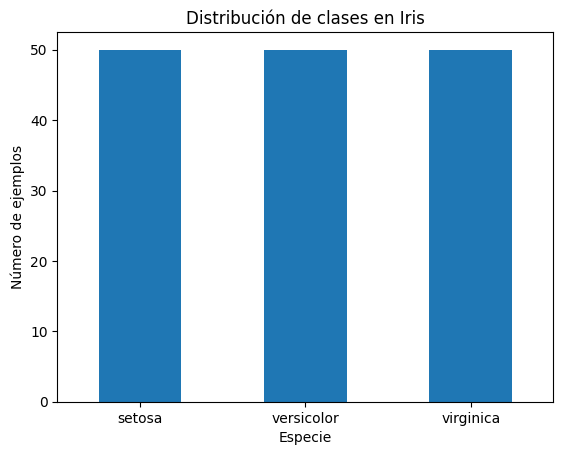

In [5]:
import matplotlib.pyplot as plt 

df["especie"].value_counts().plot(kind="bar")

plt.title("Distribución de clases en Iris")
plt.xlabel("Especie")
plt.ylabel("Número de ejemplos")
plt.xticks(rotation=0)
plt.show()

**2. Comparación de clasificadores**

1. ¿Qué modelos crees que serán sensibles a las escalas de las características?

La regresión logística, el SVM lineal y el MLP suelen ser sensibles a las diferencias de escala. Si una característica tiene valores mucho mayores que otra, puede afectar al aprendizaje. 

2. ¿Qué modelo esperas que produzca fronteras de decisión más simples?

Mi predicción inicial sería el SVM lineal, porque busca separar las clases mediante fronteras lineales.

3. ¿Por qué no podemos asegurar de antemano cuál será el mejor?

Porque el resultado depende de los datos, de la separación entre las clases, del preprocesamiento y de la capacidad del modelo para generalizar a datos que no ha visto.

El entrenamiento se le asignará el 60 % de los datos, la validación el 20 % y para la prueba el otro 20 %

**2.1. Configuraciones iniciales**

**2.2. Partición de entrenamiento**

In [6]:

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

iris = load_iris()
X = iris.data
y = iris.target

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

print(X_train.shape)
print(X_val.shape)
print(X_test.shape)


(90, 4)
(30, 4)
(30, 4)


**2.3 Implementacion de los modelos**

Primero importamos todas las librerías necesarias

In [7]:
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

ahora generamos un diccionario de modelos.

In [8]:
modelos = {
    "Naive Bayes": make_pipeline(StandardScaler(), GaussianNB()),
    "Regresion Logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "SVM Lineal": make_pipeline(StandardScaler(), SVC(kernel="linear")),
    "Árbol de decisión": make_pipeline(StandardScaler(), DecisionTreeClassifier(max_depth=3, random_state=42)),
    "Random Forest": make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=100, random_state=42)),
    "Gradient Boosting": make_pipeline(StandardScaler(), GradientBoostingClassifier(random_state=42)),
    "MLP": make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(50,), max_iter=2000, random_state=42))
}

**2.4. Comparación de accuracy y F1 macro validación**

In [9]:
resultados = []
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    predicciones = modelo.predict(X_val)
    accuracy = accuracy_score(y_val, predicciones)
    f1 = f1_score(y_val, predicciones, average="macro")

    resultados.append({
        "Modelo": nombre,
        "Accuracy validación": accuracy,
        "F1 macro validación": f1
    })

tabla = pd.DataFrame(resultados)
tabla.sort_values("F1 macro validación", ascending= False)

,Modelo,Accuracy validación,F1 macro validación
2,SVM Lineal,0.966667,0.966583
6,MLP,0.966667,0.966583
3,Árbol de decisión,0.966667,0.966583
1,Regresion Logística,0.933333,0.933333
0,Naive Bayes,0.933333,0.933333
4,Random Forest,0.933333,0.933333
5,Gradient Boosting,0.933333,0.933333


**2.5. Ajustes limitados usando validación**

In [10]:
from sklearn.model_selection import ParameterGrid

espacios = {
    "Naive Bayes": (GaussianNB, {}, {"var_smoothing": [1e-9, 1e-7, 1e-5, 1e-3]}),
    "Regresion Logística": (LogisticRegression, {"max_iter": 2000}, {"C": [0.01, 0.1, 1, 10, 100]}),
    "SVM Lineal": (SVC, {"kernel": "linear"}, {"C": [0.01, 0.1, 1, 10]}),
    "Árbol de decisión": (DecisionTreeClassifier, {"random_state": 42}, {"max_depth": [2, 3, 4, 5]}),
    "Random Forest": (RandomForestClassifier, {"random_state": 42},{"n_estimators": [100, 300], "max_depth": [3, 5, None]}),
    "Gradient Boosting": (GradientBoostingClassifier, {"random_state": 42},{"max_depth": [1, 2, 3], "learning_rate": [0.05, 0.1, 0.2]}),
    "MLP": (MLPClassifier, {"max_iter": 2000, "random_state": 42},{"hidden_layer_sizes": [(10,), (50,), (50, 25)], "alpha": [1e-4, 1e-2, 1]}),
}

def construir(clase, fijos, variables):
    return make_pipeline(StandardScaler(), clase(**fijos, **variables))

historial = []
mejores = {}  

for nombre, (clase, fijos, grilla) in espacios.items():
    mejor_clave, mejor_params = None, None
    for params in ParameterGrid(grilla):
        pred = construir(clase, fijos, params).fit(X_train, y_train).predict(X_val)
        acc = accuracy_score(y_val, pred)
        f1 = f1_score(y_val, pred, average="macro")
        historial.append({"Modelo": nombre, **params, "Accuracy val": acc, "F1 macro val": f1})
        if mejor_clave is None or (f1, acc) > mejor_clave:   
            mejor_clave, mejor_params = (f1, acc), params
    mejores[nombre] = mejor_params

historial = pd.DataFrame(historial)
pd.DataFrame([{"Modelo": n, **p} for n, p in mejores.items()]).set_index("Modelo")


,var_smoothing,C,max_depth,n_estimators,learning_rate,alpha,hidden_layer_sizes
Modelo,,,,,,,
Naive Bayes,1.000000e-09,NaN,NaN,NaN,NaN,NaN,NaN
Regresion Logística,NaN,100.0,NaN,NaN,NaN,NaN,NaN
SVM Lineal,NaN,1.0,NaN,NaN,NaN,NaN,NaN
Árbol de decisión,NaN,NaN,3.0,NaN,NaN,NaN,NaN
Random Forest,NaN,NaN,3.0,100.0,NaN,NaN,NaN
Gradient Boosting,NaN,NaN,2.0,NaN,0.05,NaN,NaN
MLP,NaN,NaN,NaN,NaN,NaN,0.0001,"(10,)"


**2.6. Congelar y evaluar en prueba**

In [11]:
modelos_finales = {
    nombre: construir(espacios[nombre][0], espacios[nombre][1], mejores[nombre])
    for nombre in espacios
}

filas = []
for nombre, modelos in modelos_finales.items():
    modelos.fit(X_train, y_train)
    pred = modelos.predict(X_test)
    filas.append({
        "Modelo": nombre,
        "Transformación": "StandardScaler",
        "Hiperparametros principales": {**espacios[nombre][1], **mejores[nombre]},
        "Accuracy de prueba": accuracy_score(y_test, pred),
        "F1 macro de prueba": f1_score(y_test, pred, average="macro"),
    })

tabla_test = pd.DataFrame(filas)
tabla_test

,Modelo,Transformación,Hiperparametros principales,Accuracy de prueba,F1 macro de prueba
0,Naive Bayes,StandardScaler,{'var_smoothing': 1e-09},0.933333,0.932660
1,Regresion Logística,StandardScaler,"{'max_iter': 2000, 'C': 100}",0.900000,0.897698
2,SVM Lineal,StandardScaler,"{'kernel': 'linear', 'C': 1}",0.933333,0.932660
3,Árbol de decisión,StandardScaler,"{'random_state': 42, 'max_depth': 3}",1.000000,1.000000
4,Random Forest,StandardScaler,"{'random_state': 42, 'max_depth': 3, 'n_estima...",0.966667,0.966583
5,Gradient Boosting,StandardScaler,"{'random_state': 42, 'learning_rate': 0.05, 'm...",0.933333,0.932660
6,MLP,StandardScaler,"{'max_iter': 2000, 'random_state': 42, 'alpha'...",0.966667,0.966583


**2.7. Resulatdos**

**2.7.1. Matrices de Confusión**

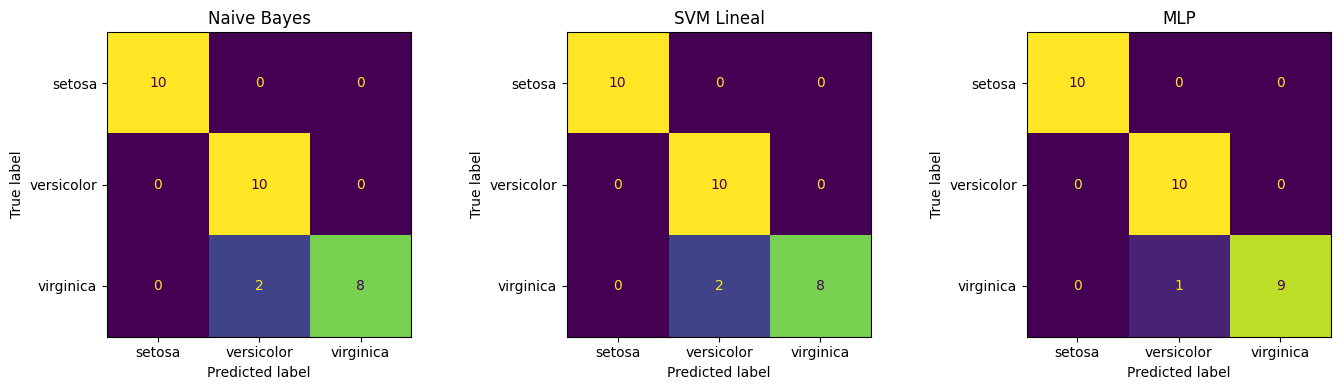

In [12]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ejes = plt.subplots(1, 3, figsize=(14,4))
for eje, nombre in zip(ejes, ["Naive Bayes", "SVM Lineal", "MLP"]):
    ConfusionMatrixDisplay.from_estimator(
        modelos_finales[nombre], X_test, y_test, display_labels=iris.target_names, ax=eje, colorbar=False
    )
    eje.set_title(nombre)
plt.tight_layout()
plt.show()

**2.7.2. Errores de clasificación**

In [13]:
import numpy as np

X_test_arr = np.asarray(X_test)
y_test_arr = np.asarray(y_test)
nombres_clase = iris.target_names

errores = []
for nombre, modelo in modelos_finales.items():
    pred = modelo.predict(X_test_arr)
    for i in np.where(pred != y_test_arr)[0]:
        errores.append({
            "Modelo": nombre, "Índice en test": i,
            "Real": nombres_clase[y_test_arr[i]], "Predicho": nombres_clase[pred[i]],
            **dict(zip(iris.feature_names, X_test_arr[i])),
        })

errores = pd.DataFrame(errores)
errores   

,Modelo,Índice en test,Real,Predicho,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,Naive Bayes,11,virginica,versicolor,6.1,2.6,5.6,1.4
1,Naive Bayes,23,virginica,versicolor,6.3,2.8,5.1,1.5
2,Regresion Logística,11,virginica,versicolor,6.1,2.6,5.6,1.4
3,Regresion Logística,23,virginica,versicolor,6.3,2.8,5.1,1.5
4,Regresion Logística,29,virginica,versicolor,6.0,3.0,4.8,1.8
5,SVM Lineal,11,virginica,versicolor,6.1,2.6,5.6,1.4
6,SVM Lineal,23,virginica,versicolor,6.3,2.8,5.1,1.5
7,Random Forest,29,virginica,versicolor,6.0,3.0,4.8,1.8
8,Gradient Boosting,23,virginica,versicolor,6.3,2.8,5.1,1.5
9,Gradient Boosting,29,virginica,versicolor,6.0,3.0,4.8,1.8


In [14]:
medias = pd.DataFrame(X_train, columns=iris.feature_names).groupby(np.asarray(y_train)).mean()
medias.index = nombres_clase
medias

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
setosa,4.986667,3.436667,1.486667,0.240000
versicolor,5.970000,2.740000,4.270000,1.313333
virginica,6.646667,3.016667,5.623333,2.056667


**2.8. Preguntas de interpretación**

1. ¿Cuál fue el modelo con el mejor desempeño?

El **Árbol de Decisión** (`max_depth=3`) obtuvo los mejores resultados, con *accuracy* y F1 macro de 1,000 (100 %) en el conjunto de prueba. Sin embargo, como solo se evaluaron 30 muestras, una diferencia de un único acierto equivale a 3,33 puntos porcentuales. Por tanto, este resultado no demuestra una superioridad general del modelo.

2. ¿Cuál fue el modelo más sencillo de programar?

**Gaussian Naive Bayes** fue el más sencillo, ya que requiere pocas configuraciones y no presenta problemas de convergencia. En comparación, el MLP necesita definir aspectos adicionales, como las capas, las funciones de activación y el número de iteraciones.

3. ¿Accuracy y F1 macro cuentan la misma historia?

En este experimento, ambas métricas muestran resultados similares porque las clases están balanceadas y los errores se concentran en una clase específica. Por ejemplo, Gaussian Naive Bayes obtuvo un *accuracy* de 0,9333 (93,33 %) y un F1 macro de 0,9327. Con clases desbalanceadas, las diferencias entre ambas métricas pueden ser mayores.

4. ¿Cuál es la diferencia entre las métricas macro y micro?

- **Macro:** calcula la métrica para cada clase y promedia los resultados, dando el mismo peso a todas las clases.
- **Micro:** reúne los aciertos y errores de todas las clases antes de calcular la métrica. En clasificación multiclase de etiqueta única, el F1 micro equivale al *accuracy*.

Por ejemplo, Gaussian Naive Bayes obtuvo 28 aciertos de 30 muestras, equivalentes a un *accuracy* de 0,9333.

5. ¿Qué aporta el MLP frente a un modelo lineal?

El **MLP** puede aprender fronteras de decisión no lineales gracias a sus funciones de activación. Aunque obtuvo mejores resultados que la SVM y la regresión logística en esta prueba, la diferencia es pequeña y no demuestra una ventaja concluyente. Además, requiere más ajustes y es menos interpretable. En el conjunto Iris, donde las clases presentan una separación relativamente sencilla, la mejora potencial puede ser limitada.


**3. Comparación de modelos de regresión**

**3.1. Importación y exploración del dataset de diabetes**

In [15]:
from sklearn.datasets import load_diabetes

diabetes = load_diabetes()
print(diabetes.DESCR)

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

Esta variables representan datos medicos de 442 pacientes con diabetes, el dataset incluye: edad, sexo, índice de masa corporal, presión arterial media, y seis medicones de suero sanguíneo.

In [16]:
diabetes_data = load_diabetes(as_frame=True)
df_features = diabetes_data.data

verificacion = pd.DataFrame({
    "Media": df_features.mean(),
    "Desviación Estandar": df_features.std(),
    "Minimo": df_features.min(),
    "Maximo": df_features.max(),
    "Suma de cuadrados": (df_features ** 2).sum()  
})
verificacion.style.format('{:.6f}')

,Media,Desviación Estandar,Minimo,Maximo,Suma de cuadrados
age,-0.000000,0.047619,-0.107226,0.110727,1.000000
sex,0.000000,0.047619,-0.044642,0.050680,1.000000
bmi,-0.000000,0.047619,-0.090275,0.170555,1.000000
bp,-0.000000,0.047619,-0.112399,0.132044,1.000000
s1,-0.000000,0.047619,-0.126781,0.153914,1.000000
s2,0.000000,0.047619,-0.115613,0.198788,1.000000
s3,-0.000000,0.047619,-0.102307,0.181179,1.000000
s4,-0.000000,0.047619,-0.076395,0.185234,1.000000
s5,0.000000,0.047619,-0.126097,0.133597,1.000000
s6,0.000000,0.047619,-0.137767,0.135612,1.000000


Practicamente la media es cero, por lo que todas las columnas estan centradas , en minimo y máximo  en el rango (-0.15,0.20); los avlores no estan en unidades biologicas reales, gracias a las uma de cuadrados podemos entender que cada vector fue normalizado.

**3.1.2. Predicción inicial**

¿Esperas que un modelo más flexibles produzca siempre un menor error en datos nuevos?

Un modelo de alta flexibilidad, es verdad, tiene bajo sesgo, pero en un dataset pequeño, como este caso de 442 muestras, causaria que el modelo caiga en overfitting, por lo que con datos nuevos el modelo no podria dar precciones correctas.

**3.2. Partición de entrenamiento y modelos de regresión**

In [17]:
X = df_features
y = diabetes_data.target

X_train, X_temp, y_train, y_temp = train_test_split(
    X,y, test_size=0.4, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)


In [18]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor

modelos = {
    "Regresión lineal": LinearRegression(),
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0, random_state=42)),
    "Lasso": make_pipeline(StandardScaler(), Lasso(alpha=1.0, random_state=42)),
    "kNN Regresor": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=5)),
    "Árbol de decisión": DecisionTreeRegressor(max_depth=4, random_state=42),
    "Radom Forest": RandomForestRegressor(n_estimators=100, max_depth = 4, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, random_state=42),
    "MLP Regresor": TransformedTargetRegressor(regressor=make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(64,32), max_iter=1000, random_state=42)),
            transformer = StandardScaler()                                   
    )
}

**3.3. Entrenamiento y evaluación en validación**

In [19]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

resultados_val = []

for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    
    y_pred_val = modelo.predict(X_val)
    
    resultados_val.append({
        'Modelo': nombre,
        'MAE': mean_absolute_error(y_val, y_pred_val),
        'RMSE': root_mean_squared_error(y_val, y_pred_val),
        'R²': r2_score(y_val, y_pred_val)
    })

df_val = pd.DataFrame(resultados_val).sort_values(by='R²', ascending=False)
df_val.style.format({'MAE': '{:.3f}', 'RMSE': '{:.3f}', 'R²': '{:.3f}'})

,Modelo,MAE,RMSE,R²
0,Regresión lineal,38.221,49.150,0.581
1,Ridge,38.294,49.203,0.580
2,Lasso,38.685,49.525,0.575
5,Radom Forest,41.341,52.504,0.522
6,Gradient Boosting,43.389,53.991,0.494
3,kNN Regresor,45.452,57.707,0.422
4,Árbol de decisión,49.193,61.250,0.349
7,MLP Regresor,53.423,66.157,0.241


**3.4. Gráficos para regresión lineal y MLP**

<>:10: SyntaxWarning: invalid escape sequence '\h'
<>:13: SyntaxWarning: invalid escape sequence '\h'
<>:18: SyntaxWarning: invalid escape sequence '\h'
<>:21: SyntaxWarning: invalid escape sequence '\h'
<>:28: SyntaxWarning: invalid escape sequence '\h'
<>:29: SyntaxWarning: invalid escape sequence '\h'
<>:35: SyntaxWarning: invalid escape sequence '\h'
<>:36: SyntaxWarning: invalid escape sequence '\h'
<>:10: SyntaxWarning: invalid escape sequence '\h'
<>:13: SyntaxWarning: invalid escape sequence '\h'
<>:18: SyntaxWarning: invalid escape sequence '\h'
<>:21: SyntaxWarning: invalid escape sequence '\h'
<>:28: SyntaxWarning: invalid escape sequence '\h'
<>:29: SyntaxWarning: invalid escape sequence '\h'
<>:35: SyntaxWarning: invalid escape sequence '\h'
<>:36: SyntaxWarning: invalid escape sequence '\h'
C:\Users\Michael Yanez\AppData\Local\Temp\ipykernel_12268\2414253909.py:10: SyntaxWarning: invalid escape sequence '\h'
  axes[0, 0].plot([y_val.min(), y_val.max()], [y_val.min(), y_va

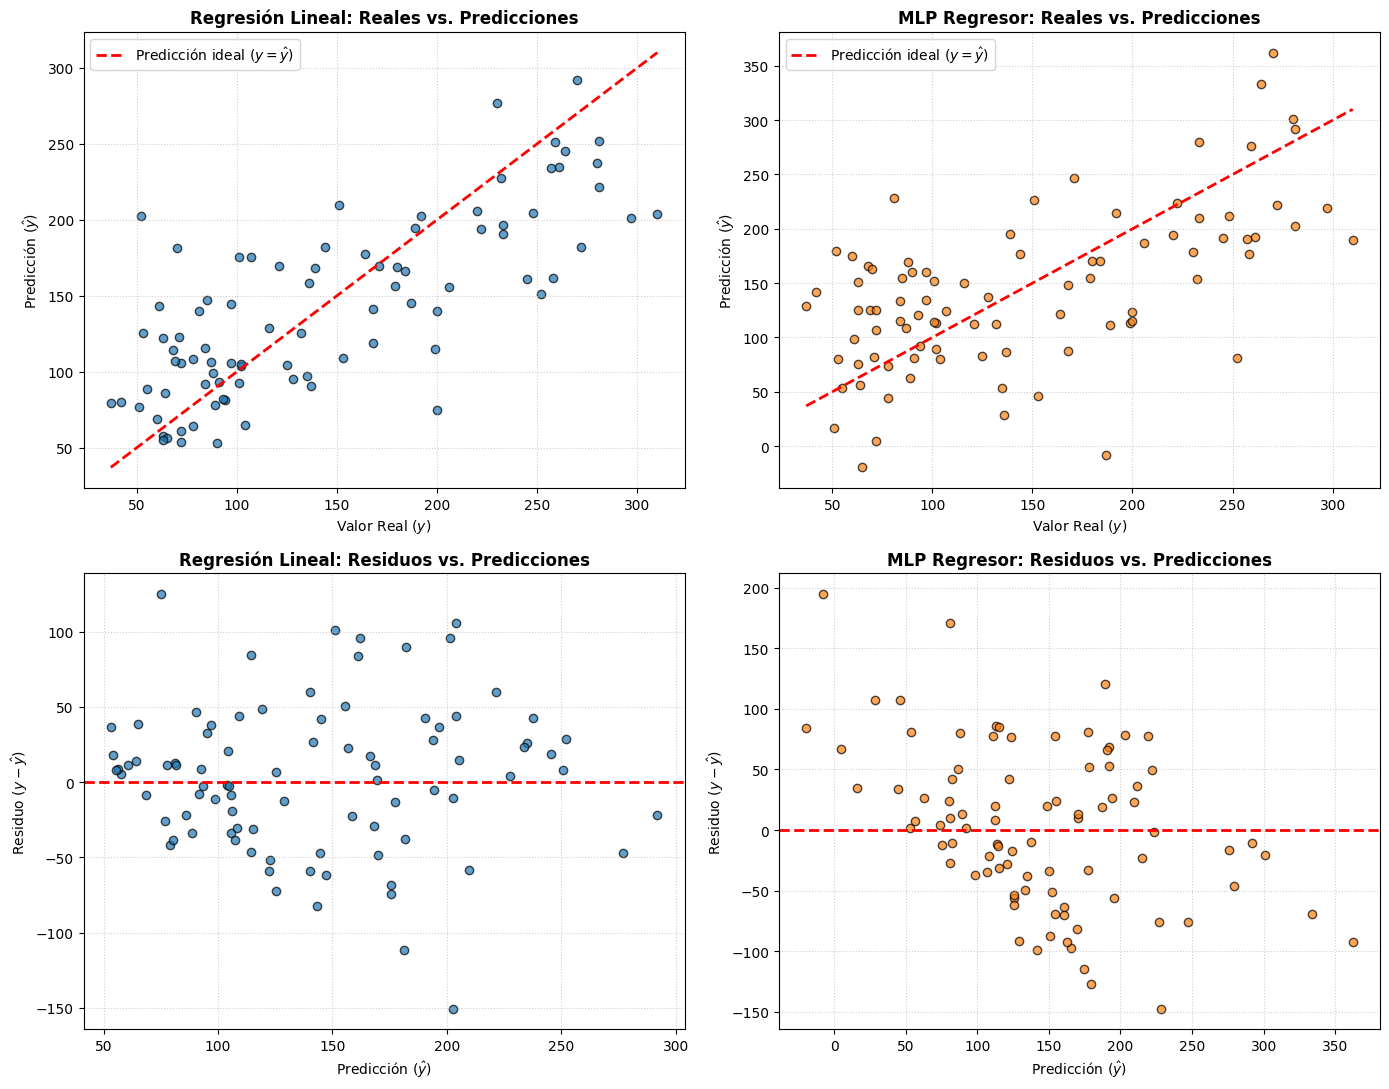

In [20]:
y_pred_lr = modelos["Regresión lineal"].predict(X_val)
y_pred_mlp = modelos["MLP Regresor"].predict(X_val)

residuos_lr = y_val - y_pred_lr
residuos_mlp = y_val - y_pred_mlp

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

axes[0, 0].scatter(y_val, y_pred_lr, color='#1f77b4', alpha=0.7, edgecolors='k')
axes[0, 0].plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()], 'r--', lw=2, label='Predicción ideal ($y = \hat{y}$)')
axes[0, 0].set_title('Regresión Lineal: Reales vs. Predicciones', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Valor Real ($y$)', fontsize=10)
axes[0, 0].set_ylabel('Predicción ($\hat{y}$)', fontsize=10)
axes[0, 0].legend()
axes[0, 0].grid(True, linestyle=':', alpha=0.6)

axes[0, 1].scatter(y_val, y_pred_mlp, color='#ff7f0e', alpha=0.7, edgecolors='k')
axes[0, 1].plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()], 'r--', lw=2, label='Predicción ideal ($y = \hat{y}$)')
axes[0, 1].set_title('MLP Regresor: Reales vs. Predicciones', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Valor Real ($y$)', fontsize=10)
axes[0, 1].set_ylabel('Predicción ($\hat{y}$)', fontsize=10)
axes[0, 1].legend()
axes[0, 1].grid(True, linestyle=':', alpha=0.6)

axes[1, 0].scatter(y_pred_lr, residuos_lr, color='#1f77b4', alpha=0.7, edgecolors='k')
axes[1, 0].axhline(0, color='r', linestyle='--', lw=2)
axes[1, 0].set_title('Regresión Lineal: Residuos vs. Predicciones', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Predicción ($\hat{y}$)', fontsize=10)
axes[1, 0].set_ylabel('Residuo ($y - \hat{y}$)', fontsize=10)
axes[1, 0].grid(True, linestyle=':', alpha=0.6)

axes[1, 1].scatter(y_pred_mlp, residuos_mlp, color='#ff7f0e', alpha=0.7, edgecolors='k')
axes[1, 1].axhline(0, color='r', linestyle='--', lw=2)
axes[1, 1].set_title('MLP Regresor: Residuos vs. Predicciones', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Predicción ($\hat{y}$)', fontsize=10)
axes[1, 1].set_ylabel('Residuo ($y - \hat{y}$)', fontsize=10)
axes[1, 1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

**3.5. Errores absolutos grandes**

In [21]:
df_errores = pd.DataFrame({
    'Valor_Real': y_val,
    'Pred_Lineal': y_pred_lr,
    'Error_Abs_Lineal': np.abs(residuos_lr),
    'Pred_MLP': y_pred_mlp,
    'Error_Abs_MLP': np.abs(residuos_mlp)
}, index=y_val.index)

top2_lineal = df_errores.nlargest(2, 'Error_Abs_Lineal')[['Valor_Real', 'Pred_Lineal', 'Error_Abs_Lineal']]

top2_mlp = df_errores.nlargest(2, 'Error_Abs_MLP')[['Valor_Real', 'Pred_MLP', 'Error_Abs_MLP']]

df_peores_casos = pd.concat([top2_lineal, top2_mlp], axis=1)
df_peores_casos.style.format('{:.2f}')

,Valor_Real,Pred_Lineal,Error_Abs_Lineal,Valor_Real,Pred_MLP,Error_Abs_MLP
56,52.00,202.65,150.65,nan,nan,nan
77,200.00,74.99,125.01,nan,nan,nan
244,nan,nan,nan,187.00,-7.94,194.94
222,nan,nan,nan,252.00,80.94,171.06


**3.5. Regularización**

**3.5.1. Evaluación de valores de $\alpha$ (Ridge vs. Lasso)**

En este caso vamos a usar un rango logarítmico de penalizaciones $\alpha$.

In [25]:

alphas = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
resultados_reg = []

for a in alphas:
    ridge = Ridge(alpha=a, random_state=42).fit(X_train, y_train)
    rmse_tr_r = root_mean_squared_error(y_train, ridge.predict(X_train))
    rmse_val_r = root_mean_squared_error(y_val, ridge.predict(X_val))
    norm_r = np.linalg.norm(ridge.coef_) 
    
    lasso = Lasso(alpha=a, random_state=42, max_iter=5000).fit(X_train, y_train)
    rmse_tr_l = root_mean_squared_error(y_train, lasso.predict(X_train))
    rmse_val_l = root_mean_squared_error(y_val, lasso.predict(X_val))
    norm_l = np.sum(np.abs(lasso.coef_))  
    nulos_l = np.sum(lasso.coef_ == 0)    
    
    resultados_reg.append({
        'alpha': a,
        'Ridge_RMSE_Train': rmse_tr_r, 'Ridge_RMSE_Val': rmse_val_r, 'Ridge_Norma_Coef': norm_r,
        'Lasso_RMSE_Train': rmse_tr_l, 'Lasso_RMSE_Val': rmse_val_l, 'Lasso_Norma_Coef': norm_l,
        'Lasso_Coef_Nulos': nulos_l
    })

df_reg = pd.DataFrame(resultados_reg)
df_reg.style.format({
    'alpha': '{:g}',
    'Ridge_RMSE_Train': '{:.2f}', 'Ridge_RMSE_Val': '{:.2f}', 'Ridge_Norma_Coef': '{:.2f}',
    'Lasso_RMSE_Train': '{:.2f}', 'Lasso_RMSE_Val': '{:.2f}', 'Lasso_Norma_Coef': '{:.2f}',
    'Lasso_Coef_Nulos': '{:d}'
})

,alpha,Ridge_RMSE_Train,Ridge_RMSE_Val,Ridge_Norma_Coef,Lasso_RMSE_Train,Lasso_RMSE_Val,Lasso_Norma_Coef,Lasso_Coef_Nulos
0,0.001,54.29,49.17,1126.65,54.29,49.16,2880.89,0
1,0.01,54.35,49.30,911.41,54.36,49.30,2146.87,0
2,0.1,54.69,49.78,763.27,54.71,50.14,1717.29,3
3,1,59.95,56.66,417.41,62.50,59.90,664.17,7
4,10,72.22,70.62,95.82,77.33,76.16,0.00,10
5,100,76.70,75.48,11.33,77.33,76.16,0.00,10


**3.5.2. Magnitud de coeficientes y curvas de error**

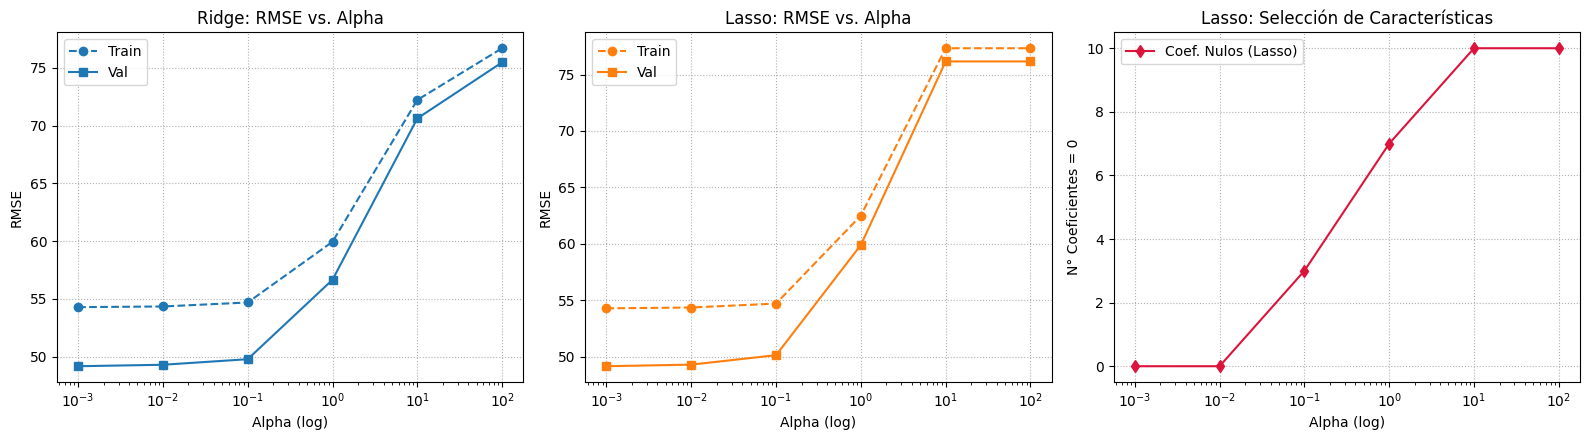

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].plot(df_reg['alpha'], df_reg['Ridge_RMSE_Train'], 'o--', label='Train', color='C0')
axes[0].plot(df_reg['alpha'], df_reg['Ridge_RMSE_Val'], 's-', label='Val', color='C0')
axes[0].set(xscale='log', title='Ridge: RMSE vs. Alpha', xlabel='Alpha (log)', ylabel='RMSE')
axes[0].grid(True, linestyle=':')
axes[0].legend()

axes[1].plot(df_reg['alpha'], df_reg['Lasso_RMSE_Train'], 'o--', label='Train', color='C1')
axes[1].plot(df_reg['alpha'], df_reg['Lasso_RMSE_Val'], 's-', label='Val', color='C1')
axes[1].set(xscale='log', title='Lasso: RMSE vs. Alpha', xlabel='Alpha (log)', ylabel='RMSE')
axes[1].grid(True, linestyle=':')
axes[1].legend()

axes[2].plot(df_reg['alpha'], df_reg['Lasso_Coef_Nulos'], 'd-', color='crimson', label='Coef. Nulos (Lasso)')
axes[2].set(xscale='log', title='Lasso: Selección de Características', xlabel='Alpha (log)', ylabel='N° Coeficientes = 0')
axes[2].grid(True, linestyle=':')
axes[2].legend()

plt.tight_layout()
plt.show()

**3.6. Congelación de configuraciones**

In [27]:
resultados_test = []

for nombre, modelo in modelos.items():
    y_pred_test = modelo.predict(X_test)
    
    resultados_test.append({
        'Modelo': nombre,
        'MAE': mean_absolute_error(y_test, y_pred_test),
        'RMSE': root_mean_squared_error(y_test, y_pred_test),
        'R²': r2_score(y_test, y_pred_test)
    })

df_test = pd.DataFrame(resultados_test).sort_values(by='R²', ascending=False)
df_test.style.format({'MAE': '{:.3f}', 'RMSE': '{:.3f}', 'R²': '{:.3f}'})

,Modelo,MAE,RMSE,R²
6,Gradient Boosting,45.491,56.138,0.455
5,Radom Forest,45.907,56.380,0.450
0,Regresión lineal,46.724,56.970,0.439
1,Ridge,46.794,57.083,0.437
2,Lasso,47.280,57.391,0.431
3,kNN Regresor,49.070,61.946,0.337
4,Árbol de decisión,49.462,64.167,0.288
7,MLP Regresor,52.496,71.114,0.126


**3.7. Interpretación**

1. ¿Qué modelo tuvo el mejor desempeño?

Los modelos lineales (**Regresión Lineal, Ridge y Lasso**) obtuvieron los mejores resultados, con menores errores y un coeficiente de determinación **R² ≈ 0.58**. Esto sugiere que la relación entre los biomarcadores y la progresión de la enfermedad es principalmente lineal, mientras que los modelos más complejos pudieron sobreajustarse a los datos.

2. ¿Por qué MAE y RMSE pueden favorecer resultados diferentes?

- **MAE:** calcula el error absoluto promedio y es menos sensible a los valores atípicos.
- **RMSE:** eleva los errores al cuadrado (x²), por lo que penaliza más los errores grandes.

Por ello, un modelo con menos errores extremos puede obtener un mejor RMSE, aunque otro tenga un MAE menor.

3. ¿Cómo se interpreta un R² negativo?

Un R² negativo indica que el modelo predice peor que utilizar la media de los valores reales como predicción constante.

4. ¿Qué efecto tuvo aumentar la regularización?

La regularización reduce la magnitud de los coeficientes y ayuda a controlar el sobreajuste. **Ridge** los aproxima a cero, mientras que **Lasso** puede eliminarlos por completo. Sin embargo, una regularización demasiado alta puede provocar subajuste y aumentar el error de predicción.

5. ¿Qué puede explicar los errores grandes?

Los errores elevados pueden deberse a variables clínicas o de estilo de vida no consideradas, pacientes con características atípicas y relaciones no lineales que los modelos no logran representar adecuadamente.

6. ¿Un coeficiente predictivo demuestra una relación causal?

**No.** Un coeficiente refleja una asociación estadística, pero no demuestra causalidad. La relación observada puede estar influida por variables no consideradas u otros factores. Para establecer causalidad se requieren estudios adecuados y métodos de inferencia causal.

### Declaración de uso de inteligencia artificial generativa

Para este trabajo se uso inteligencia artifical generativa, en la correción ortografica de de texto, asi como guía de desarrollo, correción y evaluacion en los resultados del trabajo.